# 1. Imports & Data Loading
We load the essential data science libraries and import our training and test datasets from the Kaggle directory.

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
# Import the training data to the train_data variable
train_data = pd.read_csv("/home/albert/Desktop/titanic-problem/data/train.csv")
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Import the testing data to the test_data variable
test_data = pd.read_csv("/home/albert/Desktop/titanic-problem/data/test.csv")
test_data.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


# 2. Exploratory Data Analysis (Why These Features?)
Before building our model, let's look at the data to justify our feature choices. We will check how survival rates varied by **Sex** and **Passenger Class (Pclass)**.

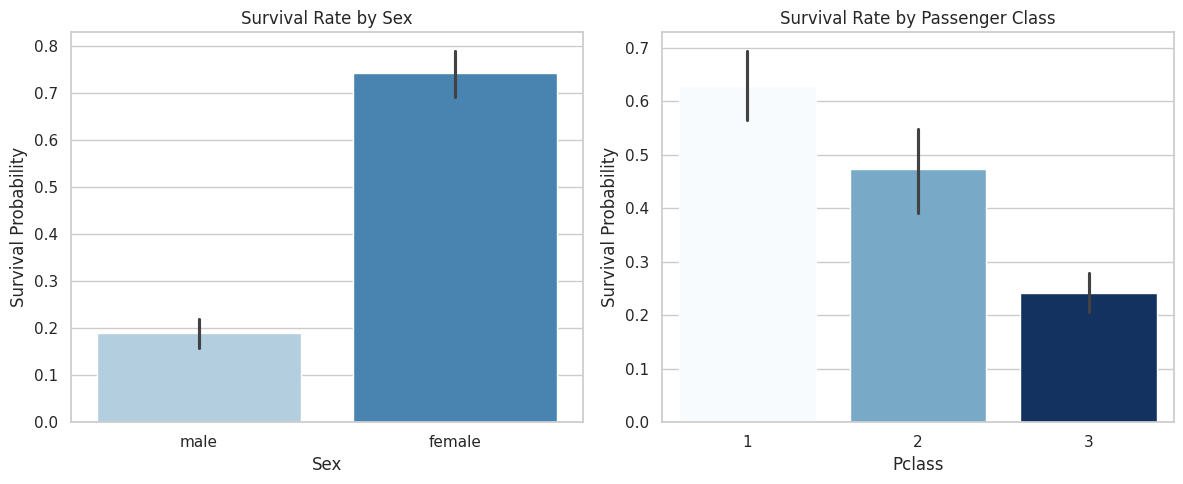

In [4]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Survival Rate by Sex
sns.barplot(data=train_data, x='Sex', y='Survived', hue='Sex', ax=axes[0], palette='Blues', legend=False)
axes[0].set_title('Survival Rate by Sex')
axes[0].set_ylabel('Survival Probability')

# 2. Survival Rate by Passenger Class
sns.barplot(data=train_data, x='Pclass', y='Survived', hue='Pclass', ax=axes[1], palette='Blues', legend=False)
axes[1].set_title('Survival Rate by Passenger Class')
axes[1].set_ylabel('Survival Probability')

plt.tight_layout()
plt.show()



# 3. Feature Selection
Based on historical context and our visual data analysis, we select our core baseline features to train the model.

In [5]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']

X = train_data[features].copy()
y = train_data['Survived']
X_test = test_data[features].copy()

# 4. Handling Missing Data (Imputation)
Machine learning models will crash if they encounter missing values (`NaN`). We fill missing ages and fares with the median value of the training set.

In [6]:
X['Age'] = X['Age'].fillna(X['Age'].median())
X_test['Age'] = X_test['Age'].fillna(X['Age'].median())
X_test['Fare'] = X_test['Fare'].fillna(X_test['Fare'].median())

# 5. Encoding Categorical Data
Models require numbers, not strings. We map the text-based 'Sex' column into binary numerical values (0 for male, 1 for female).

In [7]:
X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})
X_test['Sex'] = X_test['Sex'].map({'male': 0, 'female': 1})

# 6. Training the Random Forest Model
We initialize a Random Forest Classifier with 100 trees and a maximum depth of 5, then train it on our processed training data.

In [8]:
model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=1)
model.fit(X, y)
print("Model training complete!")

Model training complete!


# 7. Predictions & Submission File Generation
Finally, we run our test data through the trained model, format the output to match Kaggle's requirements, and save it to a CSV file.

In [9]:
predictions = model.predict(X_test)

output = pd.DataFrame({
    'PassengerId': test_data['PassengerId'], 
    'Survived': predictions
})
output.to_csv('submission.csv', index=False)
print("Submission ready!")



Submission ready!
